# 104장 · 화면 핵심 흐름 · 방향과 예시

알파 점검을 준비하며 답과 출처를 한곳에서 읽을 수 있게 하자는 시안을 만들었습니다. 102장에서 받은 응답을 이용해 장비 A의 질문부터 원문 위치까지 한 화면에 배치합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 사용자가 볼 결과 카드 만들기

완성 화면 시안　상단에 “장비 A의 점검 전 확인 사항은?”을 두고 그 아래에 “점검 전 전원 표시등을 확인합니다.”라고 씁니다. 바로 아래 ‘근거 문서’ 영역에는 자료명과 페이지·절·개정일·버전을 둡니다. 원문 바로가기 기능을 구현하는 팀은 주소를 문서 목록에서 얻고 해당 절이 열리는지 직접 확인해야 합니다.


### 셀 01 · 답변과 원문 위치 표시

로컬 예제의 Q01 응답에서 현재 답과 첫 출처를 읽어 화면 카드에 들어갈 문장을 만듭니다.

카드에는 답변과 함께 문서 이름·쪽·절·개정일을 표시합니다. RULE-A는 근거를 다시 찾을 때 쓰는 문서 ID이므로 출처 줄에도 보이게 합니다. model_calls 같은 실행 정보는 개발 기록에 남깁니다.

In [1]:
result = {'status': 'answered',
 'answer': '점검 전 전원 표시등을 확인합니다.',
 'sources': [{'id': 'RULE-A',
              'text': '점검 전 전원 표시등을 확인합니다.',
              'source': '가상 장비실 규정 A',
              'page': 1,
              'section': '2.1',
              'revised_on': '2026-11-01',
              'version': 'rules-v1'}],
 'mode': 'local_rule_fixture',
 'model_calls': 0}
source = result["sources"][0]
print(result["answer"])
print(f'근거 문서 · {source["id"]} · {source["source"]} · {source["page"]}쪽 {source["section"]}절')
print(f'개정일 {source["revised_on"]} · {source["version"]}')

점검 전 전원 표시등을 확인합니다.
근거 문서 · RULE-A · 가상 장비실 규정 A · 1쪽 2.1절
개정일 2026-11-01 · rules-v1


규정 A, 1쪽 2.1절과 개정일이 답 바로 아래에 보입니다. 줄을 나눠 놓으면 작은 화면에서도 문서 위치와 답의 문장을 따로 읽을 수 있습니다.

## 새 질문을 보낸 직후의 화면

시안의 상태 변화　보내기 전에는 질문 입력과 전송을 허용합니다. 보낸 직후에는 “응답을 기다리는 중”과 현재 요청 표식을 보여 주고 이전 답은 과거 대화에 둡니다. 새 응답을 받고 나서야 현재 답과 출처를 넣습니다. 지난 문장을 그대로 둔다면 사용자가 기다리는 중에 그 답을 새 결과로 읽을 수 있습니다.



**볼 곳**　응답 대기 중인 화면에 이전 답의 출처가 남아 있는지 보세요.

**애니메이션의 의미**　새 질문이 대기 중이면 이전 출처를 표시하지 않습니다.


### 같은 카드가 달라지는 두 시점



**볼 곳**　각 화면에서 ‘① 전송 직후 · next-01’와 ‘② 현재 요청의 응답 도착’에 표시되는 내용을 비교하세요.

**애니메이션의 의미**　새 질문이 대기 중일 때는 출처가 비어 있고, 응답이 도착해야 현재 질문의 출처를 표시합니다.

<!-- motion:clear-on-send -->
**새 요청이 대기하는 동안 무엇을 지워야 할까요?**

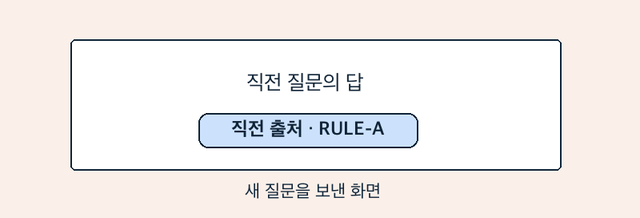

직전 질문의 답과 출처를 함께 비웁니다. 새 요청의 결과가 도착한 뒤에야 그 요청의 답과 근거를 표시합니다.
<!-- /motion -->


#### 같은 카드가 달라지는 두 시점

<div class="demo-panels"><div><small>① 전송 직후 · next-01</small><h4>장비 A 점검 전에는?</h4><p>질문을 보냈습니다. 응답을 기다리는 중입니다.</p><p>출처 0건</p></div><div><small>② 현재 요청의 응답 도착</small><h4>장비 A 점검 전에는?</h4><p>점검 전 전원 표시등을 확인합니다.</p><p><b>근거</b>　RULE-A · 가상 장비실 규정 A · 1쪽 2.1절<br>개정일 2026-11-01 · rules-v1</p></div></div><p>화면 시안입니다. 왼쪽에는 이전 답의 출처가 없고 오른쪽에는 지금 읽은 절이 답 바로 아래에 나타납니다.</p>

### 과제 02 · 선택 연습 · 대기 화면 문안

현재 답을 아직 받지 못한 경우를 담아 대기 문구를 만들어 보세요. 앞 질문의 출처를 새 카드에 복사하지 않습니다.

In [2]:
# 현재 요청 ID, 대기 문구, 비어 있는 새 출처 목록을 작성하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>view = {&quot;request_id&quot;: &quot;next-01&quot;, &quot;message&quot;: &quot;질문을 보냈습니다. 응답을 기다리는 중입니다.&quot;, &quot;sources&quot;: []}
print(view[&quot;message&quot;], view[&quot;sources&quot;])</code></pre>
<p>실행 결과</p><pre><code>질문을 보냈습니다. 응답을 기다리는 중입니다. []</code></pre>
<p>지금은 진행 안내와 빈 출처만 보입니다. 팀 화면에서는 이 안내를 어디에 둘지, 단축키나 읽기 도구로도 상태를 알 수 있을지 정할 수 있습니다.</p>
</details>

## 돌아보기

105장에는 완성된 답변 화면과, 보내는 중에는 어떤 항목이 비어 있어야 하는지 넘기세요. 노트북 출력은 화면 문안의 미리보기이며 브라우저에서 버튼을 누른 관찰 기록은 아닙니다.